In [1]:
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv("../data/raw/banking77/train.csv")
test_df = pd.read_csv("../data/raw/banking77/test.csv")

print("Train:", train_df.shape)
print("Test :", test_df.shape)

Train: (10003, 2)
Test : (3080, 2)


In [2]:
train_df.head()
train_df.tail()
train_df.sample(10)

,text,category
521,"I made an international purchase, but the exch...",card_payment_wrong_exchange_rate
9824,"I was told to verify my identity, how do I do ...",verify_my_identity
6367,Duplicate transactions appear on my account,transaction_charged_twice
4873,What do I do if I forgot my passcode?,passcode_forgotten
8573,Why did my top-up not work?,top_up_failed
7111,Why am I unable to transfer money when I was a...,beneficiary_not_allowed
5543,My transfer was rejected,declined_transfer
7400,How do I receive money from someone?,receiving_money
18,My new card has not been delivered to my home ...,card_arrival
1267,Why can't I use my card?,card_not_working


In [6]:
train_df.head()

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [4]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      10003 non-null  str  
 1   category  10003 non-null  str  
dtypes: str(2)
memory usage: 943.8 KB


In [5]:
train_df.dtypes

text        str
category    str
dtype: object

In [7]:
train_df.isnull().sum()

text        0
category    0
dtype: int64

In [8]:
print("Duplicate rows:", train_df.duplicated().sum())

Duplicate rows: 0


In [9]:
print("Duplicate texts:", train_df["text"].duplicated().sum())

Duplicate texts: 0


In [10]:
print("Number of categories:", train_df["category"].nunique())

Number of categories: 77


In [11]:
train_df["category"].unique()

<ArrowStringArray>
[                                    'card_arrival',
                                     'card_linking',
                                    'exchange_rate',
                 'card_payment_wrong_exchange_rate',
                        'extra_charge_on_statement',
                          'pending_cash_withdrawal',
                            'fiat_currency_support',
                           'card_delivery_estimate',
                                 'automatic_top_up',
                                 'card_not_working',
                                 'exchange_via_app',
                              'lost_or_stolen_card',
                                        'age_limit',
                                      'pin_blocked',
                          'contactless_not_working',
                   'top_up_by_bank_transfer_charge',
                                   'pending_top_up',
                                  'cancel_transfer',
                           

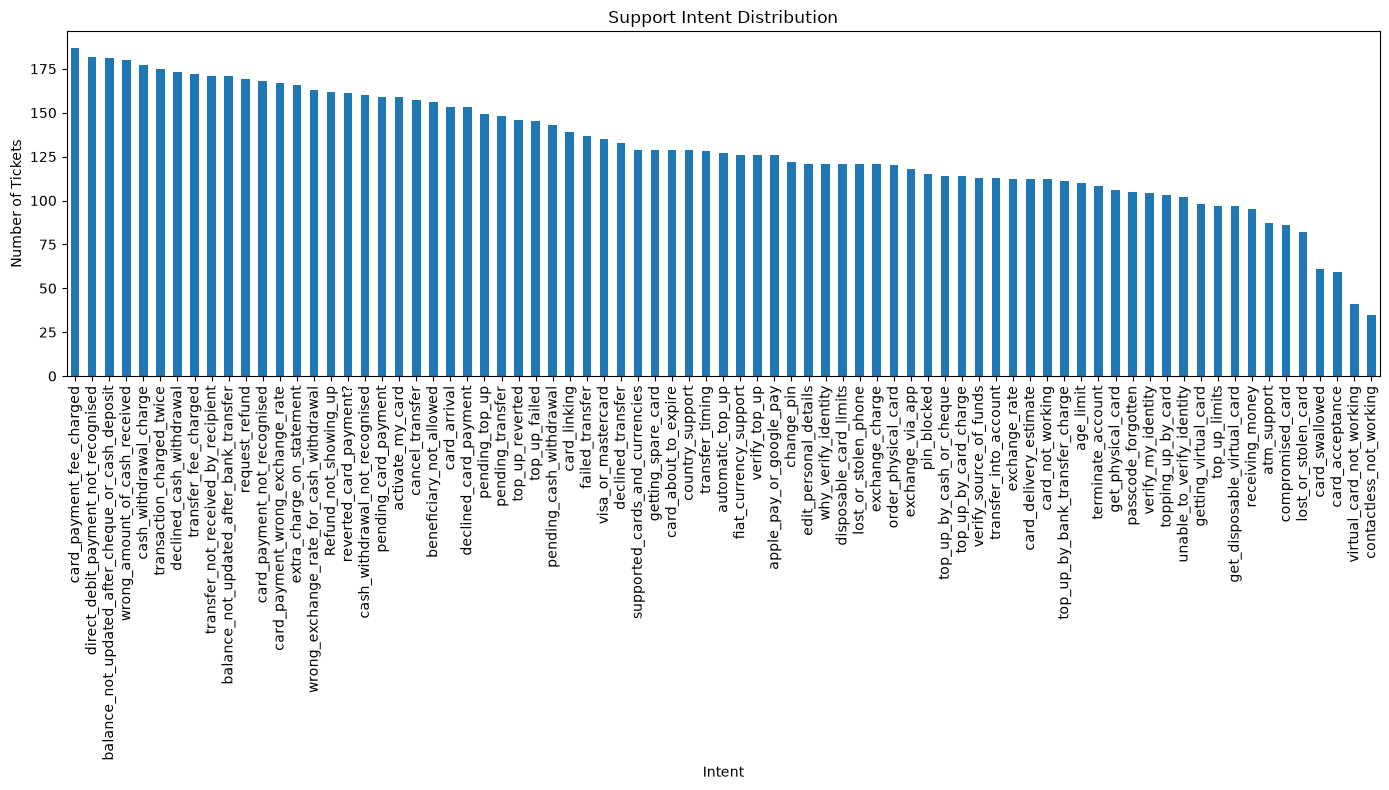

In [12]:
category_counts = train_df["category"].value_counts()

plt.figure(figsize=(14, 8))
category_counts.plot(kind="bar")
plt.title("Support Intent Distribution")
plt.xlabel("Intent")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [13]:
train_df["text_length"] = train_df["text"].str.len()

In [14]:
train_df["text_length"].describe()

count    10003.000000
mean        59.473758
std         40.867901
min         13.000000
25%         36.000000
50%         47.000000
75%         64.000000
max        433.000000
Name: text_length, dtype: float64

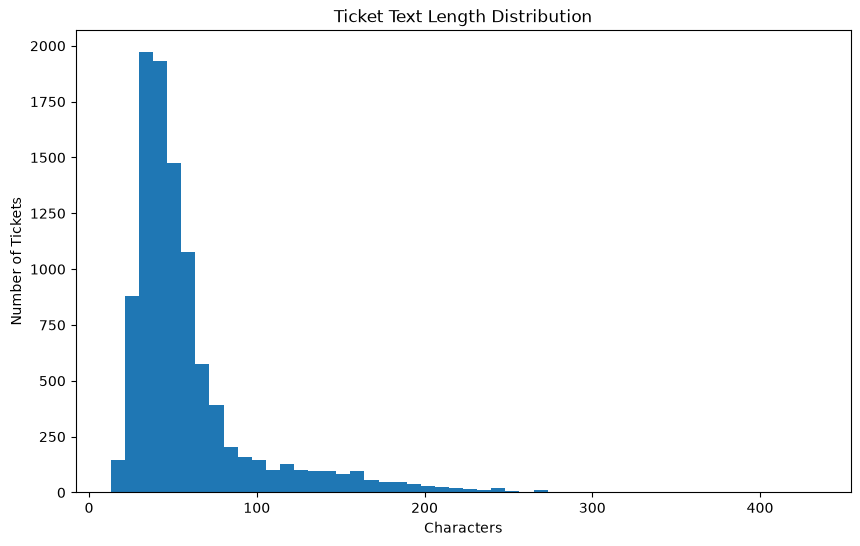

In [15]:
plt.figure(figsize=(10, 6))
plt.hist(train_df["text_length"], bins=50)
plt.title("Ticket Text Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Number of Tickets")
plt.show()

In [16]:
train_df.nlargest(10, "text_length")[["text", "category", "text_length"]]

,text,category,text_length
3917,Hearing back from us regarding your important ...,unable_to_verify_identity,433
3934,Hearing about your verification results from u...,unable_to_verify_identity,422
7310,Hi! I'm a university student studying abroad a...,transfer_fee_charged,409
3905,You will hear back from us about your verifica...,unable_to_verify_identity,381
3910,It can take between 10 minutes to an hour befo...,unable_to_verify_identity,377
7229,"I transferred 7,000 to a receiver outside the ...",transfer_fee_charged,369
5515,Hello-Can you please help me get a refund from...,request_refund,364
5997,Transfers may show up as pending for up to one...,pending_transfer,342
6439,It seems my card payment was completed twice. ...,transaction_charged_twice,339
771,"Hi there, earlier today I tried to take money ...",pending_cash_withdrawal,336


In [17]:
train_df.nsmallest(10, "text_length")[["text", "category", "text_length"]]

,text,category,text_length
2294,Can I top up?,top_up_limits,13
4003,The card PIN?,get_physical_card,13
4046,wheres my pin,get_physical_card,13
4889,Lost password,passcode_forgotten,13
5313,phone is gone,lost_or_stolen_phone,13
8547,Fix my top up,top_up_failed,13
4878,I can't log in,passcode_forgotten,14
6937,Change my pin?,change_pin,14
2368,It kept my cash,wrong_amount_of_cash_received,15
3297,Reverted top up,top_up_reverted,15


In [18]:
print("Test shape:", test_df.shape)

print("\nMissing values:")
print(test_df.isnull().sum())

print("\nDuplicate texts:")
print(test_df["text"].duplicated().sum())

print("\nNumber of categories:")
print(test_df["category"].nunique())

Test shape: (3080, 2)

Missing values:
text        0
category    0
dtype: int64

Duplicate texts:
0

Number of categories:
77
